# FEG: residual convergence for a monotone Lipschitz operator

Let $A$ be monotone and $L$-Lipschitz on a real finite-dimensional Euclidean space, with $L>0$, $A(x_\star)=0$, and $\|x_0-x_\star\|^2\le R^2$ for $R\ge0$. The horizon is an integer $N\ge1$. We study $\|A(x_N)\|^2$ for
$$x_{k+1/2}=x_k+\frac{x_0-x_k}{k+1}-\frac{k}{(k+1)L}A(x_k),$$
$$x_{k+1}=x_k+\frac{x_0-x_k}{k+1}-\frac1L A(x_{k+1/2}),\qquad 0\le k<N.$$
At $k=0$, $x_{1/2}=x_0$ is the same point and operator evaluation.

The pairwise monotonicity and Lipschitz inequalities define the numerical PEP relaxation used here; numerical optimality alone is not an arbitrary-horizon proof.

## Proof Statement

### Theorem
Let $A$ be monotone and $L$-Lipschitz in a real finite-dimensional Euclidean space, with $L>0$, $A(x_{\star})=0$, and $\|x_{0}-x_{\star}\|\le R$ for $R\ge0$. For integer $N\ge1$, use
$$x_{k+1/2}=x_{k}+\frac{x_{0}-x_{k}}{k+1}-\frac{k}{(k+1)L}A(x_{k}),\qquad
x_{k+1}=x_{k}+\frac{x_{0}-x_{k}}{k+1}-\frac1L A(x_{k+1/2}),$$
for $0\le k<N$, with $x_{1/2}=x_{0}$.
Define the normalized potential
$$V_{0}=0,\qquad V_{k}=\frac{2k^{2}}{N^{2}}\|A(x_{k})\|^{2}
+\frac{4kL}{N^{2}}\langle A(x_{k}),x_{k}-x_{0}\rangle,\quad 1\le k\le N.$$
Then $V_{k+1}\le V_{k}$, and
$$\boxed{\|A(x_{N})\|^{2}\le\frac{4L^{2}R^{2}}{N^{2}}.}$$
The potential need not be nonnegative. Its terminal identity, rather than positivity, supplies the residual bound. The result covers $N=1$ and $R=0$.

### Proof outline
Set $g_{k}=A(x_{k})$, $d=x_{0}-x_{\star}$, and define nonpositive residuals
$$\operatorname{Mon}(u,v)=-\langle A(u)-A(v),u-v\rangle,\qquad
\operatorname{Lip}(u,v)=\|A(u)-A(v)\|^{2}-L^{2}\|u-v\|^{2}.$$
For $V_{k}=2k^{2}\|g_{k}\|^{2}/N^{2}+4kL\langle g_{k},x_{k}-x_{0}\rangle/N^{2}$ and $V_{0}=0$, the shared initial half-step gives
$$V_{1}-V_{0}=\frac{2}{N^{2}}\operatorname{Lip}(x_{1},x_{0})\le0.$$
For every $1\le k<N$, substitution of both updates gives the exact identity
$$V_{k+1}-V_{k}=\frac{4Lk(k+1)}{N^{2}}\operatorname{Mon}(x_{k},x_{k+1})
+\frac{2(k+1)^{2}}{N^{2}}\operatorname{Lip}(x_{k+1},x_{k+1/2})\le0.$$
There are no other local residual or square terms. All multipliers are positive on the stated domain, so $V_{N}\le V_{0}=0$.
The terminal completion of the square is
$$\|g_{N}\|^{2}-\frac{4L^{2}R^{2}}{N^{2}}
=V_{N}+\frac{4L^{2}}{N^{2}}(\|d\|^{2}-R^{2})
+\frac{4L}{N}\operatorname{Mon}(x_{N},x_{\star})
-\left\|g_{N}-\frac{2L}{N}d\right\|^{2}.$$
Every term on the right is nonpositive: use the initial radius bound, monotonicity with $A(x_{\star})=0$, and nonnegativity of a squared norm. This proves the claimed rate. For $N=1$ the interior telescoping sum is empty; the base and terminal identities still apply. No division by $R$ or $\|g_{N}\|$ is needed.

In [1]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt

notebook_dir = Path.cwd()
REPO_ROOT = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [
    str(REPO_ROOT),
    str(notebook_dir),
    str(notebook_dir / "supplementary" / "helpers"),
]

In [2]:
import pepflow as pf
import sympy as sp

L = pf.Parameter("L")
R = pf.Parameter("R")
A = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A"], L=L)

In [3]:
def make_ctx_feg(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    """Encode N steps, sharing x_0 and x_{1/2}."""
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x0 = pf.Vector(is_basis=True, tags=["x_1/2", "x_0"])
    A.set_zero_point("x_star")
    x = x0
    for k in range(int(N)):
        anchor = x + sp.Rational(1, k + 1) * (x0 - x)
        if k == 0:
            half = x0
        else:
            half = anchor - sp.Rational(k, k + 1) / L * A(x)
            half.add_tag(f"x_{k + sp.Rational(1, 2)}")
        x = anchor - A(half) / L
        x.add_tag(f"x_{k + 1}")
    return ctx


def get_pep_setup(N, params):
    """Standard framework interface with radius R, not squared-radius R."""
    ctx = make_ctx_feg(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(A(ctx[f"x_{N}"]) ** 2)
    return ctx, pb, A

## Block 1: numerical evidence
The required sweep was run once with CLARABEL defaults, $L=R=1$. The saved sweep is reused below. The candidate is tight numerically for $N=2,\ldots,7$ and conservative at $N=1$.

N=1: 1.9999999956; status=optimal
N=2: 0.9999999961; status=optimal
N=3: 0.4444444508; status=optimal
N=4: 0.2500000070; status=optimal
N=5: 0.1600000044; status=optimal
N=6: 0.1111111199; status=optimal
N=7: 0.0816326587; status=optimal
N^2 times PEP: [2.0, 4.0, 4.0000001, 4.0000001, 4.0000001, 4.0000003, 4.0000003]


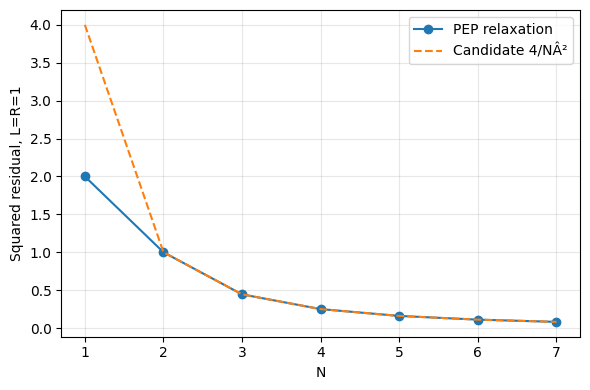

In [4]:
sweep = json.loads((notebook_dir / "state/feg_b1.json").read_text())["sweep_results"]
ns = [row["N"] for row in sweep]
values = [row["opt_value"] for row in sweep]
for row in sweep:
    print(f"N={row['N']}: {row['opt_value']:.10f}; status={row['status']}")
print("N^2 times PEP:", [round(n * n * v, 7) for n, v in zip(ns, values)])
plt.figure(figsize=(6, 4))
plt.plot(ns, values, "o-", label="PEP relaxation")
plt.plot(ns, [4 / n**2 for n in ns], "--", label="Candidate 4/NÂ²")
plt.xlabel("N")
plt.ylabel("Squared residual, L=R=1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Block 2: dense and sparse certificates
The dense and relaxed solves were performed with the visible setup and CLARABEL defaults. Saved certificates are replayed below without a new solve. All multiplier groups, the Gram remainder, and the normalization are captured together from each primal result. The numerical certificate remains distinct from an arbitrary-horizon proof.

In [5]:
import numpy as np
from pepflow.utils import Comparator
from certificate_tools import capture  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.


def acquire_certificate(n, dropped):
    live_ctx, live_pb, live_obj = get_pep_setup(n, {"L": 1, "R": 1})
    live_pb.set_relaxed_constraints(dropped)
    return capture(live_ctx, live_pb, live_obj, {"L": 1, "R": 1})


dense = json.loads((notebook_dir / "state/feg_dense.json").read_text())
b2 = json.loads((notebook_dir / "state/feg_b2.json").read_text())
N_int = b2["N_verify"]
print("Dense objective:", dense["opt_value"])
print("Basis:", dense["basis_vectors"])
for group, data in dense["lambda_groups"].items():
    matrix = np.asarray(data["matrix"])
    print(group, "entries > 1e-6:", int(np.sum(np.abs(matrix) > 1e-6)))
print("Dense S eigenvalues:", np.linalg.eigvalsh(np.asarray(dense["S_matrix"])))

Dense objective: 0.11111111987993266
Basis: ['x_0', 'x_star', 'A(x_0)', 'A(x_1)', 'A(x_3/2)', 'A(x_2)', 'A(x_5/2)', 'A(x_3)', 'A(x_7/2)', 'A(x_4)', 'A(x_9/2)', 'A(x_5)', 'A(x_11/2)', 'A(x_6)']
Monotone Operator Inequality entries > 1e-6: 6
Lipschitz Continuous Inequality entries > 1e-6: 6
Dense S eigenvalues: [8.39304623e-11 3.12048745e-10 1.29506224e-09 1.48441890e-09
 3.74263649e-09 7.48947197e-09 1.01712937e-08 1.98970904e-08
 2.28208584e-08 2.54735310e-08 2.89888702e-08 3.77429568e-08
 5.92976564e-08 1.22214889e+00]


In [6]:
dropped = [
    name
    for name, value in dense["named_dual_values"].items()
    if name != "initial_condition" and value is not None and abs(value) <= 1e-6
]
assert dropped == b2["relaxed_constraints"]
print("Dropped constraints:", len(dropped), "using threshold 1e-6")
print("Sparse objective:", b2["opt_value"])
print("Dense/sparse gap:", abs(dense["opt_value"] - b2["opt_value"]))
assert abs(dense["opt_value"] - b2["opt_value"]) < 1e-5
for name, value in b2["named_dual_values"].items():
    if value is not None:
        print(name, value)
ctx, pb, obj = get_pep_setup(N_int, {"L": 1, "R": 1})
pb.set_relaxed_constraints(dropped)
pm = pf.ExpressionManager(ctx, resolve_parameters={"L": sp.S(1), "R": sp.S(1)})
active_names = [
    name for name, value in b2["named_dual_values"].items() if value is not None
]
print("Active certificate weights:")
pf.pprint_labeled_matrix(
    np.asarray([[b2["named_dual_values"][name]] for name in active_names]),
    active_names,
    ["numerical dual"],
    precision=8,
)

Dropped constraints: 144 using threshold 1e-6
Sparse objective: 0.11111111913421273
Dense/sparse gap: 7.457199302507433e-10
initial_condition 0.11111112569910349
A monotone:x_1,x_2 0.22227319498944406
A monotone:x_2,x_3 0.6668195130842369
A monotone:x_3,x_4 1.3336389582386639
A monotone:x_4,x_5 2.2227315150486944
A monotone:x_5,x_6 3.3340972127835244
A monotone:x_6,x_star 0.6668194526134993
A Lipschitz:x_0,x_1 0.05556830706343723
A Lipschitz:x_2,x_3/2 0.2222731844438772
A Lipschitz:x_3,x_5/2 0.5001146301473184
A Lipschitz:x_4,x_7/2 0.8890926343346541
A Lipschitz:x_5,x_9/2 1.3892071926750234
A Lipschitz:x_6,x_11/2 2.000458325092437
Active certificate weights:


<IPython.core.display.Math object>

### Initial formula search
Rationalization suggested monotonicity weights $4k(k+1)/N^2$ for $(x_k,x_{k+1})$, terminal weight $4/N$ for $(x_N,x_\star)$, and Lipschitz weights $2k^2/N^2$ for $(x_k,x_{k-1/2})$. The $k=1$ Lipschitz pair is $(x_1,x_0)$.

The dominant rank-one remainder suggested $\|A(x_N)-2(x_0-x_\star)/N\|^2$ at $L=1$. These guesses do **not** match the selected numerical certificate within $10^{-4}$, as checked below. They are recorded for investigation, not substituted into the numerical certificate. General-$L$ scaling and arbitrary-horizon analytic validity remain unresolved.

In [7]:
candidate = {name: 0.0 for name in b2["named_dual_values"]}
candidate["initial_condition"] = 4 / N_int**2
for k in range(1, N_int):
    candidate[f"A monotone:x_{k},x_{k + 1}"] = 4 * k * (k + 1) / N_int**2
candidate[f"A monotone:x_{N_int},x_star"] = 4 / N_int
candidate["A Lipschitz:x_0,x_1"] = 2 / N_int**2
for k in range(2, N_int + 1):
    candidate[f"A Lipschitz:x_{k},x_{2 * k - 1}/2"] = 2 * k * k / N_int**2
lambda_error = max(
    abs(candidate[name] - (value or 0))
    for name, value in b2["named_dual_values"].items()
)
S_guess = pm.eval_scalar(
    (obj(ctx[f"x_{N_int}"]) - 2 / N_int * (ctx["x_0"] - ctx["x_star"])) ** 2
)
S_array = np.asarray(b2["S_matrix"], float)
S_guess_error = float(np.max(np.abs(S_guess.inner_prod_coords - S_array)))
print("Lambda candidate error:", lambda_error, "passes:", lambda_error <= 1e-4)
print("S candidate error:", S_guess_error, "passes:", S_guess_error <= 1e-4)
print("Analytic full PEP verified:", b2["analytic_full_pep_verified"])

Lambda candidate error: 0.0007638794501909629 passes: False
S candidate error: 0.0004583265227982025 passes: False
Analytic full PEP verified: False


### Complete numerical remainder and identity
The reverse LDL factorization retains all diagonal and off-diagonal components, including small ones. With factor rows $E$ and block-diagonal $D$, $S=E^TDE$. The signs checked below are those of the actual inequality multipliers and the complete $S$ matrix.

For residuals normalized as $r_i\le0$, the certificate identity is
$$\|A(x_N)\|^2-\mathrm{opt}-\sum_i\lambda_i r_i+\langle S,G\rangle=0.$$
The initial residual includes its constant $-R^2$. Gram, function, and offset components are all checked.

In [8]:
D = np.asarray(b2["numerical_decomposition"]["D"], float)
E = np.asarray(b2["numerical_decomposition"]["ell_coords"], float)
S_reconstructed = E.T @ D @ E
print("LDL D diagonal:", np.diag(D))
print("Reconstruction maximum error:", np.max(np.abs(S_reconstructed - S_array)))
assert np.allclose(S_reconstructed, S_array, atol=1e-4, rtol=1e-5)
pf.pprint_labeled_matrix(
    E, [f"ell_{i}" for i in range(len(E))], b2["basis_vectors"], precision=5
)
pf.pprint_labeled_matrix(D, [f"ell_{i}" for i in range(len(E))], precision=5)
print("True saved S, not the rejected analytic guess:")
pf.pprint_labeled_matrix(S_array, b2["basis_vectors"], precision=7)

LDL D diagonal: [1.00045833e+00 7.51153006e-09 2.76501551e-08 7.48731479e-09
 3.51615286e-08 6.59481809e-09 2.70457645e-08 5.40293328e-09
 1.88429287e-08 4.96182345e-09 1.18374812e-08 2.26313258e-09
 9.84068699e-09 9.28986423e-09]
Reconstruction maximum error: 5.551115123125783e-17


<IPython.core.display.Math object>

<IPython.core.display.Math object>

True saved S, not the rejected analytic guess:


<IPython.core.display.Math object>

In [9]:
def entries_for(ctx, pb):
    entries = [(c, "initial", None, None) for c in pb.init_conditions]
    for obj in list(ctx.func_to_triplets) + list(ctx.oper_to_duplets):
        groups = ctx.get_constraint_data(obj)
        assert not groups.psd_dict, (
            "This capture route requires scalar-only interpolation"
        )
        entries.extend(
            (c, "interpolation", str(obj), str(group))
            for group, constraints in groups.sc_dict.items()
            for c in constraints
        )
    assert len({c.name for c, *_ in entries}) == len(entries)
    return entries


def check_saved(ctx, pb, state, params, dense_value):
    pm = pf.ExpressionManager(ctx, resolve_parameters=params)
    basis = ctx.basis_vectors()
    assert state["basis_vectors"] == [str(v) for v in basis]
    entries = entries_for(ctx, pb)
    assert {c.name for c, *_ in entries} == set(state["named_dual_values"])
    weighted = pf.Scalar.zero()
    inequality_duals = []
    for c, *_ in entries:
        value = state["named_dual_values"][c.name]
        if state["constraint_metadata"][c.name]["relaxed"]:
            assert value is None
            continue
        assert value is not None
        residual = c.lhs - c.rhs
        if c.cmp in (Comparator.GE, Comparator.SEQ):
            residual = -residual
        weighted += float(value) * residual
        if c.cmp != Comparator.EQ:
            inequality_duals.append(float(value))
    s = np.asarray(state["S_matrix"], float)
    s_scalar = sum(
        (float(s[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(s.shape)),
        pf.Scalar.zero(),
    )
    residual = pm.eval_scalar(
        pb.performance_metric - state["opt_value"] - weighted + s_scalar
    )

    def maxabs(x):
        return float(np.max(np.abs(np.asarray(x, float)), initial=0))

    values = dict(
        identity_gram_max_abs=maxabs(residual.inner_prod_coords),
        identity_func_max_abs=maxabs(residual.func_coords),
        identity_offset_abs=maxabs(residual.offset),
        dense_relaxed_gap=abs(dense_value - state["opt_value"]),
        minimum_scalar_inequality_dual=min(inequality_duals, default=0),
        minimum_matrix_inequality_eigenvalue=0,
        minimum_S_eigenvalue=float(np.linalg.eigvalsh(s).min()),
    )
    passed = all(
        values[k] <= 1e-5
        for k in (
            "identity_gram_max_abs",
            "identity_func_max_abs",
            "identity_offset_abs",
            "dense_relaxed_gap",
        )
    )
    passed &= values["minimum_scalar_inequality_dual"] >= -1e-6
    passed &= values["minimum_S_eigenvalue"] >= -1e-6
    passed &= state["certificate_provenance"]["solver_status"] == "optimal"
    return dict(residuals=values, passed=bool(passed)), residual


checks, identity_residual = check_saved(
    ctx, pb, b2, {"L": 1, "R": 1}, dense["opt_value"]
)
print(checks)
assert checks["passed"]
pf.pprint_labeled_matrix(
    np.asarray(identity_residual.inner_prod_coords, float),
    b2["basis_vectors"],
    precision=9,
)
print("Function residual:", identity_residual.func_coords)
print("Offset residual:", identity_residual.offset)

{'residuals': {'identity_gram_max_abs': 7.512999260122766e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 6.564890756011188e-09, 'dense_relaxed_gap': 7.457199302507433e-10, 'minimum_scalar_inequality_dual': 0.05556830706343723, 'minimum_matrix_inequality_eigenvalue': 0, 'minimum_S_eigenvalue': 7.343470692425838e-10}, 'passed': True}


<IPython.core.display.Math object>

Function residual: []
Offset residual: 6.564890756011188e-09


### Block 2 conclusion
A complete, coherent numerical certificate at the selected horizon passes the fixed tolerances. The initial lambda/S search is complete, but analytic formulas remain unresolved. Blocks 3â€“4 may use the verified numerical certificate; the final analytic Lyapunov proof remains a separate obligation.

## Block 3: Lyapunov partial sums
Write $\operatorname{Mon}(u,v)=-\langle A(u)-A(v),u-v\rangle\le0$ and $\operatorname{Lip}(u,v)=\|A(u)-A(v)\|^2-L^2\|u-v\|^2\le0$.
Starting from $V_0=0$, the saved numerical weights give
$$V_{k+1}-V_k=\lambda_k\operatorname{Mon}(x_k,x_{k+1})+\mu_{k+1}\operatorname{Lip}(x_{k+1},x_{k+1/2}),$$
with the monotonicity term absent for $k=0$. Nonnegative multipliers make this convention nonincreasing. We leave the terminal $(x_N,x_\star)$ monotonicity term and the complete PSD remainder $S$ at the boundary; no weighted contribution is omitted.

The original complete LDL is retained as one PSD boundary block. The failed analytic square guess is not used. The partial sums have rank two at every nonzero index at horizons 4 and 6. The fixed comparison excludes $V_0,V_N$ and retains at least three indices per horizon. This is finite-sample discovery evidence, not a universal proof.

In [10]:
import hashlib

certificate = b2
params_sp: dict[str, pf.NUMERICAL_TYPE] = {"L": sp.S(1), "R": sp.S(1)}
ctx, pb, obj = get_pep_setup(N_int, params_sp)
pb.set_relaxed_constraints(certificate["relaxed_constraints"])
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
certificate_checked = False
certificate_keys = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)
payload = {key: certificate[key] for key in certificate_keys}
assert (
    hashlib.sha256(
        json.dumps(
            payload, sort_keys=True, separators=(",", ":"), allow_nan=False
        ).encode()
    ).hexdigest()
    == certificate["certificate_id"]
)
assert certificate["certificate_provenance"]["pep_type"] == "primal"
assert certificate["closed_form_search"]["completed"]
assert Path(pf.__file__).resolve() == REPO_ROOT / "pepflow/__init__.py"
for relative, expected in certificate["certificate_provenance"][
    "source_hashes"
].items():
    source = (notebook_dir / relative).resolve()
    assert source.is_relative_to(notebook_dir)
    assert hashlib.sha256(source.read_bytes()).hexdigest() == expected
assert json.loads(certificate["params_json"]) == {"L": 1, "R": 1}
assert certificate["N"] == N_int
basis = list(ctx.basis_vectors())
labels = [str(v) for v in basis]
assert (
    labels
    == certificate["basis_vectors"]
    == certificate["S_row_names"]
    == certificate["S_col_names"]
)
assert [str(v) for v in ctx.basis_scalars()] == certificate["basis_scalars"]
records = entries_for(ctx, pb)
assert set(certificate["constraint_metadata"]) == {c.name for c, *_ in records}
weighted_terms = {}
for constraint, origin, owner, group in records:
    name = constraint.name
    meta = dict(
        origin=origin,
        owner=owner,
        group=group,
        kind="scalar",
        comparator=constraint.cmp.value,
        shape=[],
        relaxed=name in pb.relaxed_constraints,
    )
    assert meta == certificate["constraint_metadata"][name]
    value = certificate["named_dual_values"][name]
    if meta["relaxed"]:
        assert value is None
        continue
    assert value is not None and np.isfinite(value)
    residual = constraint.lhs - constraint.rhs
    if constraint.cmp.name in ("GE", "SEQ"):
        residual = -residual
    weighted_terms[name] = float(value) * residual
tau_name = certificate["tau_name"]
assert tau_name == certificate["normalization"]["tau_name"] == "initial_condition"
assert abs(certificate["named_dual_values"][tau_name] - certificate["tau_sol"]) <= 1e-6
assert certificate["normalization"]["bound_value"] == certificate["opt_value"]
assert abs(certificate["opt_value"] - 4 / N_int**2) <= 1e-5
checks, identity_residual = check_saved(
    ctx, pb, certificate, params_sp, certificate["opt_value"]
)
assert checks["passed"]
S_array = np.asarray(certificate["S_matrix"], float)
assert np.all(np.isfinite(S_array)) and np.allclose(
    S_array, S_array.T, atol=1e-6, rtol=0
)
assert np.linalg.eigvalsh(S_array).min() >= -1e-6
D = np.asarray(certificate["numerical_decomposition"]["D"], float)
E = np.asarray(certificate["numerical_decomposition"]["ell_coords"], float)
assert certificate["numerical_decomposition"]["basis_labels"] == labels
assert D.shape == (len(E), len(E)) and E.shape[1] == len(basis)
assert np.all(np.isfinite(D)) and np.all(np.isfinite(E))
assert np.allclose(E.T @ D @ E, S_array, atol=1e-4, rtol=1e-5)
certificate_checked = True

print("Replayed complete certificate:", certificate_checked)
print(checks["residuals"])

Replayed complete certificate:

 True
{'identity_gram_max_abs': 7.512999260122766e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 6.564890756011188e-09, 'dense_relaxed_gap': 0.0, 'minimum_scalar_inequality_dual': 0.05556830706343723, 'minimum_matrix_inequality_eigenvalue': 0, 'minimum_S_eigenvalue': 7.343470692425838e-10}


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\feg\r01\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



In [11]:
# The failed analytic S guess is not used. Retain the complete numerical LDL
# together as one PSD boundary block, including all small factor contributions.
ell = [sum((float(c) * v for c, v in zip(row, basis)), pf.Vector.zero()) for row in E]
S_scalar = sum(
    (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)), pf.Scalar.zero()
)
S_piece_terms = {"complete_S": S_scalar}
decomposition_residual = (
    np.asarray(pm.eval_scalar(S_scalar).inner_prod_coords, float) - S_array
)
assert np.max(np.abs(decomposition_residual)) <= 1e-5
S_assignment = {"complete_S": "boundary"}

print("Complete-S block reconstruction error:", np.max(np.abs(decomposition_residual)))

Complete-S block reconstruction error: 5.551115123125783e-17


In [12]:
grouping_checked = False
rank_tolerance = 1e-4
rank_left, rank_right = 1, 1
group_terms = {name: term for name, term in weighted_terms.items() if name != tau_name}
term_assignment = {}
for name in group_terms:
    if name == f"A monotone:x_{N_int},x_star":
        term_assignment[name] = "boundary"
    elif name.startswith("A monotone:"):
        first, second = name.split(":")[1].split(",")
        k = int(first.split("_")[1])
        assert second == f"x_{k + 1}"
        term_assignment[name] = k
    elif name == "A Lipschitz:x_0,x_1":
        term_assignment[name] = 0
    elif name.startswith("A Lipschitz:"):
        first, second = name.split(":")[1].split(",")
        k = int(first.split("_")[1])
        assert second == f"x_{2 * k - 1}/2"
        term_assignment[name] = k - 1
    else:
        raise ValueError(f"Unassigned contribution: {name}")
assert set(term_assignment) == set(group_terms)
lyap = [pf.Scalar.zero()]
partial_sum = pf.Scalar.zero()
for step in range(N_int):
    partial_sum += sum(
        (
            group_terms[name]
            for name, target in term_assignment.items()
            if target == step
        ),
        pf.Scalar.zero(),
    )
    partial_sum -= sum(
        (
            S_piece_terms[name]
            for name, target in S_assignment.items()
            if target == step
        ),
        pf.Scalar.zero(),
    )
    lyap.append(partial_sum)
ranks, singular_values = [], []
for k, Vk in enumerate(lyap):
    matrix = np.asarray(pm.eval_scalar(Vk).inner_prod_coords, float)
    singular = np.linalg.svd(matrix, compute_uv=False)
    rank = int(np.sum(singular > rank_tolerance))
    ranks.append(rank)
    singular_values.append(singular.tolist())
    print(f"rank V_{k}: {rank}")
    if k == 0:
        print()
print(
    "Interior rank is constant at this N:",
    len(set(ranks[rank_left : N_int + 1 - rank_right])) == 1,
    "boundary exclusions:",
    (rank_left, rank_right),
)
boundary_names = [name for name, step in term_assignment.items() if step == "boundary"]
boundary_S = [name for name, step in S_assignment.items() if step == "boundary"]
assert len(boundary_names) <= 1 and len(boundary_S) <= 1
leftover = (
    sum((group_terms[name] for name in boundary_names), pf.Scalar.zero()) - S_scalar
)
coverage_diff = (
    lyap[N_int] + leftover - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
)
coverage_residual = pm.eval_scalar(coverage_diff)
for coords in (
    coverage_residual.inner_prod_coords,
    coverage_residual.func_coords,
    coverage_residual.offset,
):
    assert np.max(np.abs(np.asarray(coords, float)), initial=0) <= 1e-5
for piece in S_piece_terms.values():
    evaluated = pm.eval_scalar(piece)
    assert (
        np.max(np.abs(evaluated.func_coords), initial=0) <= 1e-5
        and abs(evaluated.offset) <= 1e-5
    )
    assert (
        np.linalg.eigvalsh(np.asarray(evaluated.inner_prod_coords, float)).min()
        >= -1e-6
    )
for k in range(N_int):
    increment = sum(
        (group_terms[name] for name, step in term_assignment.items() if step == k),
        pf.Scalar.zero(),
    )
    change = pm.eval_scalar(lyap[k + 1] - lyap[k] - increment)
    for coords in (change.inner_prod_coords, change.func_coords, change.offset):
        assert np.max(np.abs(np.asarray(coords, float)), initial=0) <= 1e-5
    # All included terms are nonnegative multiples of residuals <= 0,
    # hence the chosen convention gives V_{k+1} <= V_k numerically.
    assert all(
        certificate["named_dual_values"][name] >= -1e-6
        for name, step in term_assignment.items()
        if step == k
    )
grouping_checked = True

rank V_0: 0

rank V_1: 2
rank V_2: 2
rank V_3: 2
rank V_4: 2
rank V_5: 2
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)


In [13]:
rank_evidence = json.loads(
    (notebook_dir / "supplementary/rank_search.json").read_text()
)
for sample in rank_evidence["samples"]:
    retained = sample["rank_profile"][1 : sample["N"]]
    assert len(retained) >= 3 and set(retained) == {2}
    print(
        f"N={sample['N']}: rank 2 at {len(retained)} retained indices; certificate and coverage checked"
    )
print("Fixed exclusions: (1,1); absolute unscaled rank tolerance: 1e-4")
print(
    "Selected coverage:",
    grouping_checked,
    "boundary interpolation terms:",
    len(boundary_names),
    "boundary PSD blocks:",
    len(boundary_S),
)

N=4: rank 2 at 3 retained indices; certificate and coverage checked
N=6: rank 2 at 5 retained indices; certificate and coverage checked
Fixed exclusions: (1,1); absolute unscaled rank tolerance: 1e-4
Selected coverage: True boundary interpolation terms: 1 boundary PSD blocks: 1


## Identify the vectors composing the Lyapunov function
The selected B3 certificate and partial sums are replayed above. We seek interpretable vectors spanning each quadratic form, including the terminal index. Rank zero at the initial index uses an empty basis.

In [14]:
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
    find_symmetric_coefficient_matrix,
)

b3 = json.loads((notebook_dir / "state/feg_b3.json").read_text())
assert certificate_checked and grouping_checked
assert ranks == b3["rank_profile"]
assert b3["rank_search"]["confirmed_horizons"] == [4, 6]
for k, Vk in enumerate(lyap):
    evaluated = pm.eval_scalar(Vk)
    assert np.allclose(
        evaluated.inner_prod_coords,
        b3["lyap_inner_prod_coords"][k],
        atol=1e-4,
        rtol=1e-5,
    )
    assert np.allclose(
        evaluated.func_coords, b3["lyap_func_coords"][k], atol=1e-4, rtol=1e-5
    )
    assert abs(evaluated.offset - b3["lyap_offsets"][k]) <= 1e-4
print("Reconstructed B3 data agree; interior 1..N-1, exceptions 0 and N.")

Reconstructed B3 data agree; interior 1..N-1, exceptions 0 and N.


### Candidate-vector scan
Candidates include tagged full and half iterates, operator outputs, original coordinate vectors, anchor gaps, and pairwise differences. Duplicates and zero vectors are removed by coordinates, preferring the meaningful anchor-gap labels.

In [15]:
candidate_pairs = []
for k in range(1, N_int + 1):
    candidate_pairs.extend(
        [(f"g_{k}", obj(ctx[f"x_{k}"])), (f"x_{k}-x_0", ctx[f"x_{k}"] - ctx["x_0"])]
    )
base = [(str(v), v) for v in ctx.basis_vectors()]
base += [(f"x_{k}", ctx[f"x_{k}"]) for k in range(N_int + 1)]
base += [(f"x_{2 * k + 1}/2", ctx[f"x_{2 * k + 1}/2"]) for k in range(1, N_int)]
candidate_pairs.extend(base)
for i, (label_i, vi) in enumerate(base):
    for label_j, vj in base[i + 1 :]:
        candidate_pairs.append((f"({label_i})-({label_j})", vi - vj))
unique_pairs, unique_coords = [], []
for label, v in candidate_pairs:
    coords = np.asarray(pm.eval_vector(v).coords, float)
    if np.linalg.norm(coords) <= 1e-12:
        continue
    if any(np.allclose(coords, old, atol=1e-12, rtol=0) for old in unique_coords):
        continue
    unique_pairs.append((label, v))
    unique_coords.append(coords)
candidates = [v for _, v in unique_pairs]
label_by_id = {id(v): label for label, v in unique_pairs}
print("Unique nonzero candidates:", len(candidates))
in_column = {}
for k in range(1, N_int + 1):
    in_column[k] = vectors_in_column_space(
        lyap[k],
        candidates,
        pep_context=ctx,
        resolve_parameters=params_sp,
        rtol=1e-4,
        atol=1e-4,
    )
    print(f"V_{k} column-space candidates:")
    for v in in_column[k]:
        print("   " + label_by_id[id(v)])

Unique nonzero candidates: 342
V_1 column-space candidates:
   g_1
   x_1-x_0
   A(x_0)
   (x_0)-(x_3/2)
   (A(x_0))-(A(x_1))
   (x_1)-(x_3/2)
V_2 column-space candidates:
   g_2
   x_2-x_0
   (x_0)-(x_2)
   (x_0)-(x_5/2)
   (x_2)-(x_5/2)


V_3 column-space candidates:
   g_3
   x_3-x_0
   (x_0)-(x_3)
   (x_0)-(x_7/2)
   (x_3)-(x_7/2)
V_4 column-space candidates:
   g_4
   x_4-x_0
   (x_0)-(x_4)
   (x_0)-(x_9/2)
   (x_4)-(x_9/2)


V_5 column-space candidates:
   g_5
   x_5-x_0
   (x_0)-(x_5)
   (x_0)-(x_11/2)
   (x_5)-(x_11/2)
V_6 column-space candidates:
   g_6
   x_6-x_0
   (x_0)-(x_6)


### Selected basis pattern
The actual sparsity search is retained below for every nonzero index.

In [16]:
search_results = {}
for k in range(1, N_int + 1):
    sparse_basis, C_sparse = find_basis_with_sparsest_coefficients(
        lyap[k],
        in_column[k],
        pep_context=ctx,
        resolve_parameters=params_sp,
        zero_tol=1e-6,
        indep_tol=1e-7,
        span_tol=1e-5,
    )
    assert len(sparse_basis) == ranks[k]
    chosen_labels = [label_by_id[id(v)] for v in sparse_basis]
    search_results[k] = {"labels": chosen_labels, "matrix": C_sparse.tolist()}
    print(f"k={k}, rank={ranks[k]} sparse basis: {chosen_labels}")
    print(f"zero coefficients: {np.sum(np.abs(C_sparse) < 1e-6)}/{C_sparse.size}")

k=1, rank=2 sparse basis: ['x_1-x_0', '(A(x_0))-(A(x_1))']
zero coefficients: 2/4
k=2, rank=2 sparse basis: ['x_2-x_0', '(x_2)-(x_5/2)']
zero coefficients: 2/4


k=3, rank=2 sparse basis: ['x_3-x_0', '(x_3)-(x_7/2)']
zero coefficients: 2/4


k=4, rank=2 sparse basis: ['x_4-x_0', '(x_4)-(x_9/2)']
zero coefficients: 2/4


k=5, rank=2 sparse basis: ['x_5-x_0', '(x_5)-(x_11/2)']
zero coefficients: 2/4
k=6, rank=2 sparse basis: ['g_6', 'x_6-x_0']
zero coefficients: 1/4


The sparsest interior coordinates involve the next half iterate. For a single pattern valid through the terminal index, adopt the equally spanning basis
$$v_{1,k}=A(x_k),\qquad v_{2,k}=x_k-x_0,\qquad 1\le k\le N.$$
The initial quadratic part $V_0=0$ uses the empty basis. Independence and reconstruction of this adopted basis are checked below, so this change of coordinates is not inferred from the sparse search alone.

In [17]:
def V_k_basis(k):
    return [] if k == 0 else [obj(ctx[f"x_{k}"]), ctx[f"x_{k}"] - ctx["x_0"]]


def V_k_basis_labels(k):
    return [] if k == 0 else [f"A(x_{k})", f"x_{k}-x_0"]


for k in range(N_int + 1):
    vecs = V_k_basis(k)
    independent_rank = (
        int(
            np.linalg.matrix_rank(
                np.column_stack([pm.eval_vector(v).coords for v in vecs]).astype(float),
                tol=1e-7,
            )
        )
        if vecs
        else 0
    )
    assert independent_rank == len(vecs) == ranks[k]
    print(f"k={k}: rank {independent_rank} basis {V_k_basis_labels(k)}")

k=0: rank 0 basis []
k=1: rank 2 basis ['A(x_1)', 'x_1-x_0']
k=2: rank 2 basis ['A(x_2)', 'x_2-x_0']
k=3: rank 2 basis ['A(x_3)', 'x_3-x_0']
k=4: rank 2 basis ['A(x_4)', 'x_4-x_0']
k=5: rank 2 basis ['A(x_5)', 'x_5-x_0']
k=6: rank 2 basis ['A(x_6)', 'x_6-x_0']


### Coefficient matrices
The ordered basis is $[A(x_k),x_k-x_0]$ for every $1\le k\le N$. With symmetric $C$, the expression is $\sum_{i,j} C_{ij}\langle v_i,v_j\rangle$; off-diagonal entries contribute twice. Empty function-coordinate arrays and zero offsets are verified rather than discarded.

In [18]:
coeff_by_k, coefficient_residuals = {}, {}
for k in range(N_int + 1):
    vecs = V_k_basis(k)
    C = find_symmetric_coefficient_matrix(
        lyap[k],
        vecs,
        pep_context=ctx,
        resolve_parameters=params_sp,
        indep_tol=1e-7,
        span_tol=1e-5,
    )
    target = np.asarray(pm.eval_scalar(lyap[k]).inner_prod_coords, float)
    matrix = (
        np.column_stack([pm.eval_vector(v).coords for v in vecs]).astype(float)
        if vecs
        else np.zeros((len(ctx.basis_vectors()), 0))
    )
    residual = float(np.linalg.norm(matrix @ C @ matrix.T - target, ord="fro"))
    assert residual <= 1e-5 * max(1.0, np.linalg.norm(target, ord="fro"))
    coeff_by_k[k], coefficient_residuals[k] = C, residual
    print(f"k={k}: coefficient reconstruction residual {residual:.3g}")
    if vecs:
        pf.pprint_labeled_matrix(
            C, V_k_basis_labels(k), V_k_basis_labels(k), precision=8
        )
    else:
        print("Empty quadratic basis, C shape", C.shape)
    nonquadratic = pm.eval_scalar(lyap[k])
    assert np.max(np.abs(nonquadratic.func_coords), initial=0) <= 1e-5
    assert abs(nonquadratic.offset) <= 1e-5
    print(
        "Function coordinates:",
        nonquadratic.func_coords,
        "offset:",
        nonquadratic.offset,
    )

k=0: coefficient reconstruction residual 0
Empty quadratic basis, C shape (0, 0)
Function coordinates: [] offset: 0.0
k=1: coefficient reconstruction residual 1.96e-17


<IPython.core.display.Math object>

Function coordinates: [] offset: 0
k=2: coefficient reconstruction residual 1.89e-08


<IPython.core.display.Math object>

Function coordinates: [] offset: 0


k=3: coefficient reconstruction residual 2.58e-08


... (6 outputs left out)

<IPython.core.display.Math object>

Function coordinates: [] offset: 0
k=6: coefficient reconstruction residual 5.51e-08


<IPython.core.display.Math object>

Function coordinates: [] offset: 0


In [19]:
def V_k_structure(k):
    vecs = V_k_basis(k)
    C = coeff_by_k[k]
    return sum(
        (float(C[i, j]) * vecs[i] * vecs[j] for i, j in np.ndindex(C.shape)),
        pf.Scalar.zero(),
    )


component_residuals = {}
for k in range(N_int + 1):
    diff = pm.eval_scalar(V_k_structure(k) - lyap[k])
    target = pm.eval_scalar(lyap[k])
    component_residuals[str(k)] = {}
    for name, residual, reference in (
        ("gram", diff.inner_prod_coords, target.inner_prod_coords),
        ("function", diff.func_coords, target.func_coords),
        ("offset", diff.offset, target.offset),
    ):
        error = float(np.max(np.abs(np.asarray(residual, float)), initial=0))
        scale = float(np.max(np.abs(np.asarray(reference, float)), initial=0))
        assert error <= 1e-4 + 1e-5 * scale
        component_residuals[str(k)][name] = error
print("Complete expression reconstruction:", component_residuals)

Complete expression reconstruction:

 {'0': {'gram': 0.0, 'function': 0.0, 'offset': 0.0}, '1': {'gram': 1.3877787807814457e-17, 'function': 0.0, 'offset': 0.0}, '2': {'gram': 1.0952467932590082e-08, 'function': 0.0, 'offset': 0.0}, '3': {'gram': 1.5489513477406902e-08, 'function': 0.0, 'offset': 0.0}, '4': {'gram': 2.3334075449632508e-08, 'function': 0.0, 'offset': 0.0}, '5': {'gram': 3.1022639013222886e-08, 'function': 0.0, 'offset': 0.0}, '6': {'gram': 3.1022639013222886e-08, 'function': 0.0, 'offset': 0.0}}


### Block 4 conclusion
The observed complete structure is $V_0=0$ and
$$V_k=c_{00}(k,N,L)\|A(x_k)\|^2+2c_{01}(k,N,L)\langle A(x_k),x_k-x_0\rangle+c_{11}(k,N,L)\|x_k-x_0\|^2,$$
for $1\le k\le N$, with no function-value or constant terms. All required numerical reconstructions pass, including both endpoints. At the B4 handoff the coefficient functions were unresolved; the next section derives them and prove the exact step, base, and boundary identities. This section records the numerical discovery stage.

## Block 5: exact coefficient derivation
The B4 sample is retained as numerical evidence. The symbolic ansatz uses its basis and leaves all three symmetric coefficients and both local multipliers unknown. We solve the recurrence identities exactly rather than rounding the numerical certificate.

In [20]:
from typing import Any

b4 = json.loads((notebook_dir / "state/feg_b4.json").read_text())
assert b4["certificate_id"] == b3["certificate_id"]
assert b4["numerical_reconstruction"]["required_indices"] == list(range(N_int + 1))
print("Basis:", b4["basis_templates"])
print("Unknown coefficient roles:", b4["unresolved_coefficients"])


def symbolic_components(expression, manager):
    value = manager.eval_scalar(pf.Scalar.zero() + expression, sympy_mode=True)
    gram = sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify)
    functions = sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify)
    offset = sp.simplify(sp.sympify(value.offset))
    return gram, functions, offset


def verify_symbolic_identity(name, expression, manager):
    gram, functions, offset = symbolic_components(expression, manager)
    labels = [str(v) for v in manager.context.basis_vectors()]
    print(name, "Gram residual shape:", gram.shape)
    pf.pprint_labeled_matrix(np.asarray(gram.tolist(), dtype=object), labels, labels)
    print(name, "function residual:", functions, "offset:", offset)
    assert all(term == 0 for term in [*gram, *functions, offset]), name
    return True

Basis: ['A(x_k)', 'x_k-x_0']
Unknown coefficient roles: [{'name': 'c_00', 'arguments': ['k', 'N', 'L'], 'role': 'C[0,0]', 'index_domain': '1 <= k <= N'}, {'name': 'c_01', 'arguments': ['k', 'N', 'L'], 'role': 'C[0,1] = C[1,0]', 'index_domain': '1 <= k <= N'}, {'name': 'c_11', 'arguments': ['k', 'N', 'L'], 'role': 'C[1,1]', 'index_domain': '1 <= k <= N'}]


### Symbolic recursion context and coefficient equations
Let $V_{k}=a_{k}\|g_{k}\|^{2}+2b_{k}\langle g_{k},x_{k}-x_{0}\rangle+c_{k}\|x_{k}-x_{0}\|^{2}$. We require
$$V_{k+1}-V_{k}=\lambda_{k}\operatorname{Mon}(x_{k},x_{k+1})+\mu_{k}\operatorname{Lip}(x_{k+1},x_{k+1/2}).$$
The next cell constructs the actual two updates with symbolic $k,L,N$, extracts every Gram/function/offset equation, and solves jointly for the coefficients and multipliers.

In [21]:
k_sym, N_sym = sp.symbols("k N", integer=True, positive=True)
L_sym = sp.Symbol("L", positive=True)
k_par, N_par, L_par = pf.Parameter("k"), pf.Parameter("N"), pf.Parameter("L_local")
ctx_step = pf.PEPContext("symbolic_feg_step").set_as_current()
A_step = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{step}"], L=L_par)
x_anchor = pf.Vector(is_basis=True, tags=["x_{0}"])
x_current = pf.Vector(is_basis=True, tags=["x_{k}"])
g_current = A_step(x_current)
anchor_step = x_current + (x_anchor - x_current) / (k_par + 1)
x_half = anchor_step - k_par / ((k_par + 1) * L_par) * g_current
x_half.add_tag("x_{k+1/2}")
g_half = A_step(x_half)
x_next = anchor_step - g_half / L_par
x_next.add_tag("x_{k+1}")
g_next = A_step(x_next)
mon_step = -(x_current - x_next) * (g_current - g_next)
lip_step = (g_next - g_half) ** 2 - L_par**2 * (x_next - x_half) ** 2
unknown_names = (
    "a",
    "b",
    "c",
    "a_plus",
    "b_plus",
    "c_plus",
    "lambda_local",
    "mu_local",
)
unknown_symbols = sp.symbols(" ".join(unknown_names), real=True)
unknown_parameters = {name: pf.Parameter(name) for name in unknown_names}
a, b, c, ap, bp, cp, lam, mu = [unknown_parameters[name] for name in unknown_names]
V_ansatz = (
    a * g_current**2
    + 2 * b * g_current * (x_current - x_anchor)
    + c * (x_current - x_anchor) ** 2
)
V_next_ansatz = (
    ap * g_next**2
    + 2 * bp * g_next * (x_next - x_anchor)
    + cp * (x_next - x_anchor) ** 2
)
step_ansatz_diff = V_next_ansatz - V_ansatz - lam * mon_step - mu * lip_step
symbolic_parameters: dict[str, Any] = {
    "k": k_sym,
    "N": N_sym,
    "L_local": L_sym,
    **dict(zip(unknown_names, unknown_symbols)),
}
pm_derivation = pf.ExpressionManager(ctx_step, resolve_parameters=symbolic_parameters)
gram_unknown, func_unknown, offset_unknown = symbolic_components(
    step_ansatz_diff, pm_derivation
)
equations = [
    term for term in [*gram_unknown, *func_unknown, offset_unknown] if term != 0
]
solution_list = sp.solve(equations, list(unknown_symbols[1:]), dict=True)
assert len(solution_list) == 1
coefficient_solution = {
    symbol: sp.factor(value) for symbol, value in solution_list[0].items()
}
print("Exact local coefficient solution:", coefficient_solution)
a_sym, b_sym, c_sym, ap_sym, bp_sym, cp_sym, lam_sym, mu_sym = unknown_symbols
assert (
    sp.simplify(coefficient_solution[ap_sym] / a_sym - (k_sym + 1) ** 2 / k_sym**2) == 0
)
assert sp.simplify(coefficient_solution[b_sym] - a_sym * L_sym / k_sym) == 0
assert coefficient_solution[c_sym] == 0 and coefficient_solution[cp_sym] == 0
normalization_constant = sp.S(2) / N_sym**2
derived_substitution = {a_sym: normalization_constant * k_sym**2}
derived_values = {
    a_sym: derived_substitution[a_sym],
    **{
        symbol: sp.factor(value.subs(derived_substitution))
        for symbol, value in coefficient_solution.items()
    },
}
print("Normalized coefficients:", derived_values)
print(
    "V_k LaTeX:",
    sp.latex(2 * k_sym**2 / N_sym**2),
    "||A(x_k)||^2 +",
    sp.latex(4 * k_sym * L_sym / N_sym**2),
    "<A(x_k),x_k-x_0>",
)

Exact local coefficient solution: {a_plus: a*(k + 1)**2/k**2, b: L*a/k, b_plus: L*a*(k + 1)/k**2, c: 0, c_plus: 0, lambda_local: 2*L*a*(k + 1)/k, mu_local: a*(k + 1)**2/k**2}
Normalized coefficients: {a: 2*k**2/N**2, a_plus: 2*(k + 1)**2/N**2, b: 2*L*k/N**2, b_plus: 2*L*(k + 1)/N**2, c: 0, c_plus: 0, lambda_local: 4*L*k*(k + 1)/N**2, mu_local: 2*(k + 1)**2/N**2}
V_k LaTeX: \frac{2 k^{2}}{N^{2}} ||A(x_k)||^2 + \frac{4 L k}{N^{2}} <A(x_k),x_k-x_0>


### Resolved recurrence and normalization
The equations give
$$a_{k+1}=a_{k}\frac{(k+1)^{2}}{k^{2}},\quad b_{k}=\frac{La_{k}}{k},\quad c_{k}=0,\quad
\lambda_{k}=\frac{2La_{k}(k+1)}{k},\quad\mu_{k}=a_{k}\frac{(k+1)^{2}}{k^{2}}.$$
Thus $a_{k}=\gamma k^{2}$ for a constant positive scale $\gamma$. We choose $\gamma=2/N^{2}$; the base and terminal identities below verify that this normalization yields the claimed performance bound, so a homogeneous zero solution is not being used.

The selected floating-point certificate has a slightly different common scale. We report raw differences honestly and also check the scale-invariant numerical pattern. This does not replace or change any saved multipliers or $S$. The exact proof concerns the newly derived normalized potential.

In [22]:
def coeff_pattern(k, n, ell):
    if k == 0:
        return sp.zeros(0, 0)
    return sp.Matrix(
        [
            [2 * sp.S(k) ** 2 / sp.S(n) ** 2, 2 * sp.S(k) * ell / sp.S(n) ** 2],
            [2 * sp.S(k) * ell / sp.S(n) ** 2, 0],
        ]
    )


numeric_scale = float(coeff_by_k[1][0, 0]) * N_int**2 / 2
print("Positive sample scale relative to the analytic normalization:", numeric_scale)
assert numeric_scale > 0
for index in range(1, N_int + 1):
    exact_C = coeff_pattern(index, N_int, sp.S(1))
    raw_error = np.max(np.abs(coeff_by_k[index] - np.asarray(exact_C, float)))
    scale_adjusted_error = np.max(
        np.abs(coeff_by_k[index] / numeric_scale - np.asarray(exact_C, float))
    )
    print(
        f"k={index}: raw difference {raw_error:.3g}; after common positive scale {scale_adjusted_error:.3g}"
    )
    assert scale_adjusted_error <= 1e-5
    pf.pprint_labeled_matrix(
        np.asarray(exact_C, dtype=object),
        V_k_basis_labels(index),
        V_k_basis_labels(index),
    )

Positive sample scale relative to the analytic normalization: 1.0002295271418702
k=1: raw difference 1.28e-05; after common positive scale 1.39e-17


<IPython.core.display.Math object>

k=2: raw difference 5.1e-05; after common positive scale 4.38e-08


<IPython.core.display.Math object>

k=3: raw difference 0.000115; after common positive scale 1.33e-07


<IPython.core.display.Math object>

... (2 outputs left out)

k=5: raw difference 0.000318; after common positive scale 4.84e-07


<IPython.core.display.Math object>

k=6: raw difference 0.000458; after common positive scale 7.29e-07


<IPython.core.display.Math object>

### Closed-form Lyapunov function
The derived analytic potential is
$$V_{0}=0,\qquad V_{k}=\frac{2k^{2}}{N^{2}}\|A(x_{k})\|^{2}+\frac{4kL}{N^{2}}\langle A(x_{k}),x_{k}-x_{0}\rangle\quad(1\le k\le N).$$
There are no function-value, scalar-offset, or additional terminal-basis terms. We now verify this potential's exact one-step identity and its separate base and terminal cases.

## Symbolic Step Recursion Verification

For $1\le k<N$, verify
$$V_{k+1}-V_{k}=\frac{4Lk(k+1)}{N^{2}}\operatorname{Mon}(x_{k},x_{k+1})+\frac{2(k+1)^{2}}{N^{2}}\operatorname{Lip}(x_{k+1},x_{k+1/2}).$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish in every scalar component.

In [23]:
V_step = (
    2 * k_par** 2 / N_par** 2 * g_current** 2
    + 4 * k_par * L_par / N_par** 2 * g_current * (x_current - x_anchor)
)
V_step_next = 2 * (k_par + 1) ** 2 / N_par**2 * g_next**2 + 4 * (
    k_par + 1
) * L_par / N_par**2 * g_next * (x_next - x_anchor)
step_LHS = V_step_next - V_step
step_RHS = (
    4 * L_par * k_par * (k_par + 1) / N_par**2 * mon_step
    + 2 * (k_par + 1) ** 2 / N_par**2 * lip_step
)
step_diff = step_LHS - step_RHS
step_parameters: dict[str, Any] = {"k": k_sym, "N": N_sym, "L_local": L_sym}
pm_step = pf.ExpressionManager(ctx_step, resolve_parameters=step_parameters)
step_verified = verify_symbolic_identity("Step", step_diff, pm_step)

Step Gram residual shape: (5, 5)


<IPython.core.display.Math object>

Step function residual: Matrix(0, 0, []) offset: 0


## Base Case and Boundary Symbolic Verification

Use the actual initial update $x_{1}=x_{0}-A(x_{0})/L$ and shared point $x_{1/2}=x_{0}$ to verify
$$V_{1}-V_{0}=\frac{2}{N^{2}}\operatorname{Lip}(x_{1},x_{0}),\qquad V_{0}=0.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero. The positive multiplier and Lipschitz condition imply $V_{1}\le0$. This verification applies to every $N\ge1$.

In [24]:
ctx_base = pf.PEPContext("symbolic_feg_base").set_as_current()
A_base = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{base}"], L=L_par)
x_base0 = pf.Vector(is_basis=True, tags=["x_{0}", "x_{1/2}"])
g_base0 = A_base(x_base0)
x_base1 = x_base0 - g_base0 / L_par
x_base1.add_tag("x_{1}")
g_base1 = A_base(x_base1)
base_lip = (g_base1 - g_base0) ** 2 - L_par**2 * (x_base1 - x_base0) ** 2
base_LHS = 2 / N_par**2 * g_base1**2 + 4 * L_par / N_par**2 * g_base1 * (
    x_base1 - x_base0
)
base_RHS = 2 / N_par**2 * base_lip
base_diff = base_LHS - base_RHS
base_parameters: dict[str, Any] = {"N": N_sym, "L_local": L_sym}
pm_base = pf.ExpressionManager(ctx_base, resolve_parameters=base_parameters)
base_verified = verify_symbolic_identity("Base", base_diff, pm_base)

Base Gram residual shape: (3, 3)


<IPython.core.display.Math object>

Base function residual: Matrix(0, 0, []) offset: 0


### Boundary Identity Symbolic Verification

With $d=x_{0}-x_{\star}$, verify
$$\|A(x_{N})\|^{2}-\frac{4L^{2}R^{2}}{N^{2}}
=V_{N}+\frac{4L^{2}}{N^{2}}(\|d\|^{2}-R^{2})+\frac{4L}{N}\operatorname{Mon}(x_{N},x_{\star})
-\left\|A(x_{N})-\frac{2L}{N}d\right\|^{2}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish, including the constant involving $R^{2}$.

In [25]:
ctx_boundary = pf.PEPContext("symbolic_feg_boundary").set_as_current()
A_boundary = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{boundary}"], L=L_par)
x_bound0 = pf.Vector(is_basis=True, tags=["x_{0}"])
x_boundN = pf.Vector(is_basis=True, tags=["x_{N}"])
x_boundstar = A_boundary.set_zero_point("x_{star}")
g_boundN = A_boundary(x_boundN)
R_par = pf.Parameter("R_local")
R_sym = sp.Symbol("R", nonnegative=True)
V_terminal = 2 * g_boundN**2 + 4 * L_par / N_par * g_boundN * (x_boundN - x_bound0)
initial_residual = (x_bound0 - x_boundstar) ** 2 - R_par**2
terminal_mon = -(x_boundN - x_boundstar) * g_boundN
terminal_square = (g_boundN - 2 * L_par / N_par * (x_bound0 - x_boundstar)) ** 2
boundary_LHS = g_boundN**2 - 4 * L_par**2 * R_par**2 / N_par**2
boundary_RHS = (
    V_terminal
    + 4 * L_par**2 / N_par**2 * initial_residual
    + 4 * L_par / N_par * terminal_mon
    - terminal_square
)
boundary_diff = boundary_LHS - boundary_RHS
boundary_parameters: dict[str, Any] = {"N": N_sym, "L_local": L_sym, "R_local": R_sym}
pm_boundary = pf.ExpressionManager(ctx_boundary, resolve_parameters=boundary_parameters)
boundary_verified = verify_symbolic_identity("Boundary", boundary_diff, pm_boundary)

Boundary Gram residual shape: (4, 4)


<IPython.core.display.Math object>

Boundary function residual: Matrix(0, 0, []) offset: 0


### Signs, domain, and conclusion
For integer $N\ge1$, $1\le k<N$, and $L>0$, all displayed multipliers are positive and every denominator is nonzero. Monotonicity and Lipschitz continuity make the residuals nonpositive, while the terminal squared norm is nonnegative. Hence the potential decreases from zero, and the terminal identity proves the stated residual bound. The proof uses no nonnegativity assumption on the potential, no division by $R$, and no finite-horizon interpolation claim beyond the given inequalities. The local analytic Lyapunov proof is complete; the earlier global numerical certificate remains a distinct object with unresolved analytic formulas.

In [26]:
sign_coefficients = {
    "monotonicity": 4 * L_sym * k_sym * (k_sym + 1) / N_sym**2,
    "Lipschitz": 2 * (k_sym + 1) ** 2 / N_sym**2,
    "base": 2 / N_sym**2,
    "initial": 4 * L_sym**2 / N_sym**2,
    "terminal": 4 * L_sym / N_sym,
}
assert all(value.is_positive is True for value in sign_coefficients.values())
assert (L_sym * N_sym * k_sym * (k_sym + 1)).is_nonzero is True
print("All active multipliers positive for L>0, N>=1, k>=1; R>=0.")
print("Step applies for 1<=k<N; N=1 uses only the base and terminal identities.")
print(
    "Every residual is nonpositive, the square is nonnegative, V_N<=V_0=0, hence ||A(x_N)||Â²<=4LÂ²RÂ²/NÂ²."
)

assert step_verified and base_verified and boundary_verified
print(
    "Exact local Lyapunov theorem verified; global numerical-certificate formula status remains separate."
)

All active multipliers positive for L>0, N>=1, k>=1; R>=0.
Step applies for 1<=k<N; N=1 uses only the base and terminal identities.
Every residual is nonpositive, the square is nonnegative, V_N<=V_0=0, hence ||A(x_N)||Â²<=4LÂ²RÂ²/NÂ².
Exact local Lyapunov theorem verified; global numerical-certificate formula status remains separate.
